# Data overview

A look at the prepared data: the three content types, the dev/test split and the low-resolution inputs at each JPEG quality. Run `code/datasets/download_data.py` and `code/datasets/prepare_data.py` first.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
JPEG_QUALITIES = ["none", 50, 30, 10]

manifest = pd.read_csv(PROCESSED_DIR / "manifest.csv")
manifest.head()

,image_id,content,split,source,font,font_size,kind,text
0,object_0801,objects,test,DIV2K/0801.png,NaN,NaN,NaN,NaN
1,object_0802,objects,test,DIV2K/0802.png,NaN,NaN,NaN,NaN
2,object_0803,objects,test,DIV2K/0803.png,NaN,NaN,NaN,NaN
3,object_0804,objects,dev,DIV2K/0804.png,NaN,NaN,NaN,NaN
4,object_0805,objects,dev,DIV2K/0805.png,NaN,NaN,NaN,NaN


## Images per content type and split

In [2]:
manifest.groupby(["content", "split"]).size().unstack()

split,dev,test
content,,
faces,20,100
objects,20,80
text,24,96


## Text images

Every combination of font, font size and kind (dictionary words or random codes) appears equally often. A font size of 16 px in the 512x512 image is only 4 px in the 128x128 input.

In [3]:
text = manifest[manifest["content"] == "text"]
text.groupby(["split", "font_size", "kind"]).size().unstack()

kind             codes  words
split font_size              
dev   16.0           3      3
      24.0           3      3
      32.0           3      3
      48.0           3      3
test  16.0          12     12
      24.0          12     12
      32.0          12     12
      48.0          12     12

## Ground truth and low-resolution inputs

Each row is one dev image: the 512x512 ground truth, then the 128x128 input at each JPEG quality (enlarged without smoothing, so the real pixels are visible).

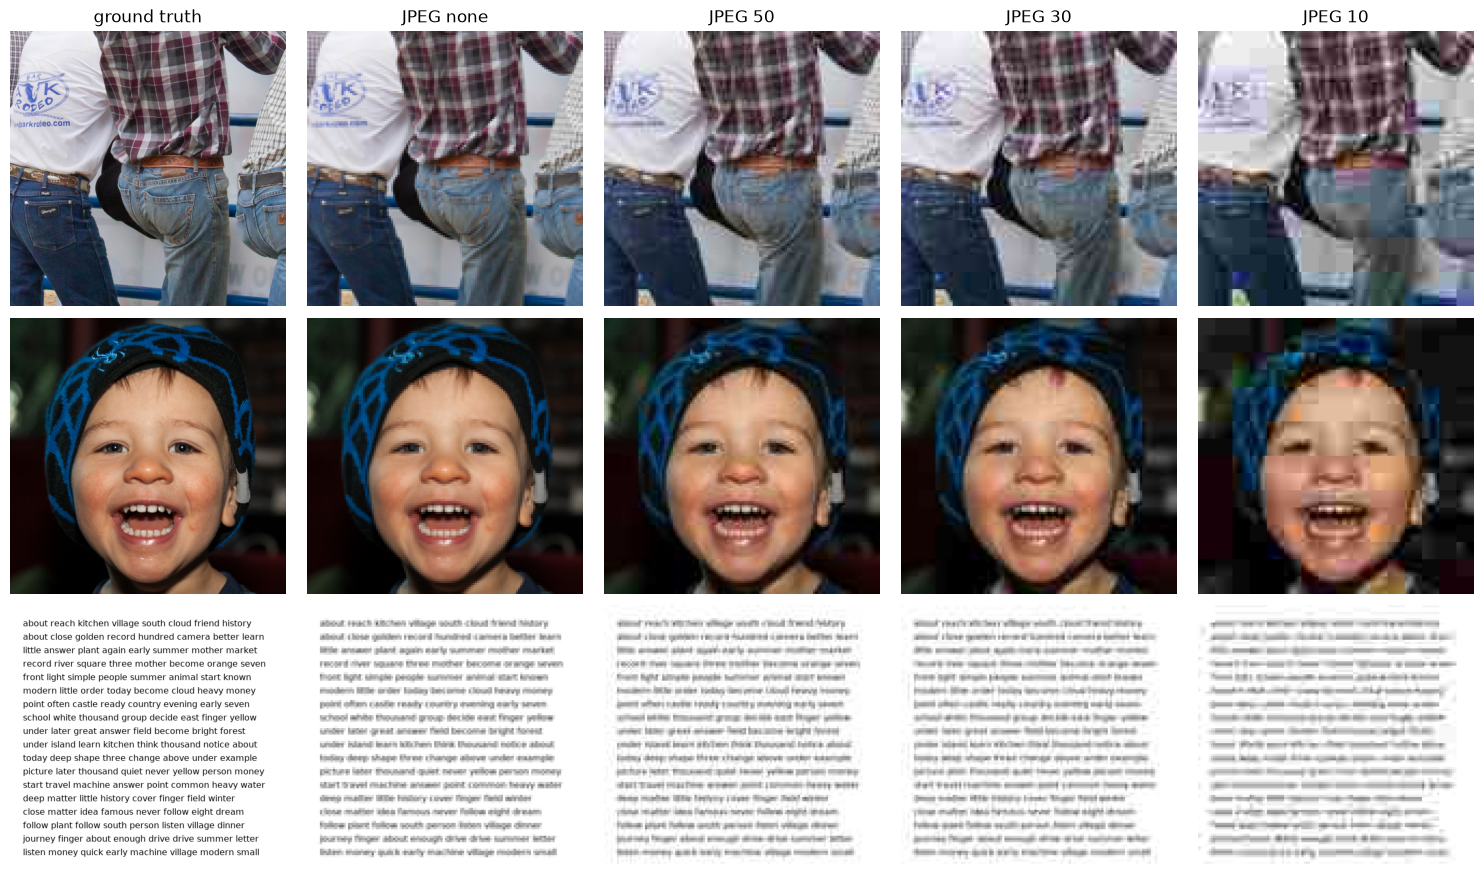

In [4]:
dev = manifest[manifest["split"] == "dev"]
examples = [dev[dev["content"] == content].iloc[0] for content in ["objects", "faces", "text"]]

figure, axes = plt.subplots(len(examples), len(JPEG_QUALITIES) + 1, figsize=(15, 9))
for row, example in enumerate(examples):
    axes[row, 0].imshow(Image.open(PROCESSED_DIR / "hr" / f"{example.image_id}.png"))
    axes[row, 0].set_title("ground truth" if row == 0 else "")
    for column, quality in enumerate(JPEG_QUALITIES, start=1):
        low_resolution = Image.open(PROCESSED_DIR / "lr" / f"jpeg_{quality}" / f"{example.image_id}.png")
        axes[row, column].imshow(low_resolution.resize((512, 512), Image.NEAREST))
        axes[row, column].set_title(f"JPEG {quality}" if row == 0 else "")
for axis in axes.ravel():
    axis.axis("off")
figure.tight_layout()

## Font sizes

The same font at the four sizes, as the model sees it (128x128 input, no JPEG).

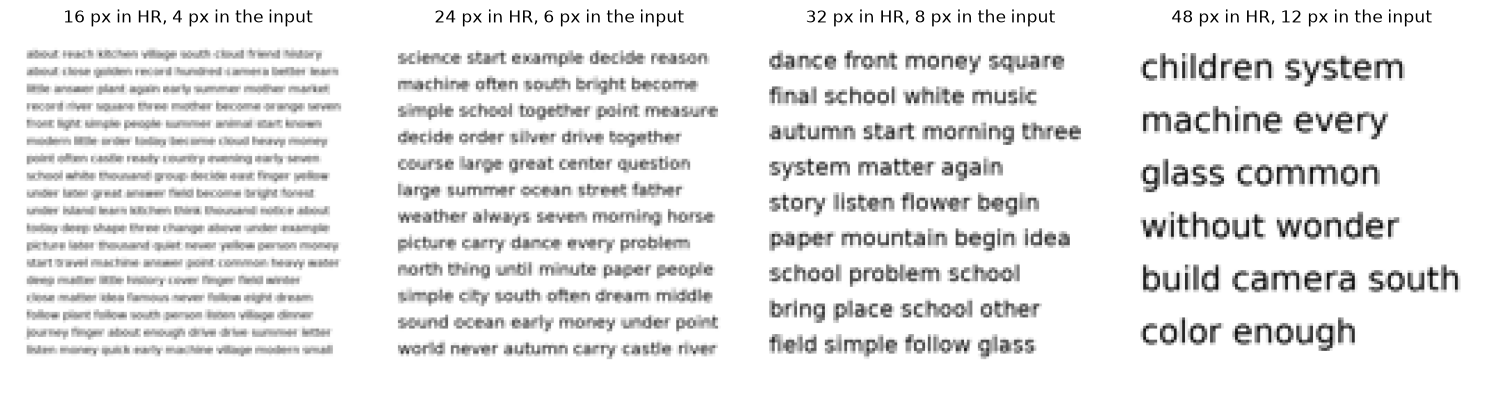

In [5]:
sans_words = dev[(dev["font"] == "DejaVuSans.ttf") & (dev["kind"] == "words")].sort_values("font_size")

figure, axes = plt.subplots(1, len(sans_words), figsize=(15, 4))
for axis, example in zip(axes, sans_words.itertuples()):
    low_resolution = Image.open(PROCESSED_DIR / "lr" / "jpeg_none" / f"{example.image_id}.png")
    axis.imshow(low_resolution.resize((512, 512), Image.NEAREST))
    axis.set_title(f"{int(example.font_size)} px in HR, {int(example.font_size) // 4} px in the input")
    axis.axis("off")
figure.tight_layout()